In [1]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm



In [2]:

# df_obl = pd.read_csv (r"D:\!Work\IFA\!data\Urban_fluxes_NE\raw\Tomsk\Oblkom\2023_rot3\moment_06_2023_oblkom_10Hz_26m_rot3_bp20_v202502.csv", sep = ';', parse_dates=['data'], dayfirst=True).set_index('data') 
# df_imc = pd.read_csv (r"D:\!Work\IFA\!data\Urban_fluxes_NE\raw\Tomsk\IMCES40m\2023_rot3\moment_06_2023_imces_80Hz_40m_rot3_bp20.csv", sep = ';', parse_dates=['data'], dayfirst=True).set_index('data') 

# df_imc.index = df_imc.index - pd.Timedelta(hours=7)

# #%matplotlib qt

# plt.figure()
# df_obl['P'].plot()
# (df_imc['P'] + (df_obl['P'] - df_imc['P']).mean()).plot()


In [2]:

data_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/raw/Tomsk"

sites = ['BEK', 'Oblkom', 'IMCES40m', 'IMCES30m', 'IMCES30m_mezo']

corr_str = 'rot3'

df4sites = {}

for site in sites:
    display(site)
    df4site = pd.DataFrame()
    for file in tqdm (glob.glob(data_dir + '/' + site + '/20*' + corr_str + '/' + 'moment*.csv')):
    #for file in tqdm (glob.glob(data_dir + '/' + site + '/20*/' + 'moment*.csv')):
    
        cur_df = pd.read_csv (file, sep = ';', parse_dates=['data'], dayfirst=True).set_index('data') 
        cur_df = cur_df.apply(pd.to_numeric, errors='coerce')

        if site == 'IMCES40m':
            idx = np.where(cur_df.index >= pd.Timestamp(2025,6,17,23,0,0))[0]
            new_index = cur_df.index.values
            new_index[idx] -= pd.Timedelta(hours=9)

            cur_df.index = new_index

            idx = np.where(cur_df.index <= pd.Timestamp(2023,7,1))[0]
            new_index = cur_df.index.values
            new_index[idx] -= pd.Timedelta(hours=7)

            cur_df.index = new_index


        modal_year = pd.Series(cur_df.index.year).mode()[0]
        if str(modal_year) not in os.path.basename(file):
        #if (pd.Timestamp(2024,2,1) in cur_df.index):
            print(file, modal_year)
        
        if 'uz' not in cur_df.columns:
            cur_df['uz'] = np.sqrt (cur_df['uw']**2 + cur_df['vw']**2)
            
        df4site = pd.concat((df4site, cur_df))
        df4site = df4site.sort_index()

    if df4site.shape[0] == 0:
        continue

    #df4site['V_old'] = df4site['V']
    df4site['V_raw'] = np.sqrt(df4site['Vs']**2 + df4site['Ve']**2)
    df4site['V'] = np.sqrt(df4site['u']**2 + df4site['v']**2)

    #df4site['rho'] = df4site['tau'] / (df4site['uz'] ** 2)
    #df4site['Cd'] = (df4site['uz'] / df4site['V']) **2
    
    #ustar2u_ratio = df4site['uz'] / df4site['V']
    #display(ustar2u_ratio.quantile(0.99))
    #df4site.loc[ustar2u_ratio > 1, 'Cd'] = np.nan
    
    #df4site = df4site.rename(columns={c: site + '_' + c for c in df4site.columns})
    #df = df.merge(df4site, how = 'outer', right_index = True, left_index = True)        

    time_arr = pd.date_range(pd.Timestamp(df4site.index.date[0]), pd.Timestamp(df4site.index.date[-1]), freq = '20min') 
    df4site = df4site.resample('20min').last() 
    df4site = df4site.reindex(time_arr)
    
    df4sites[site] = df4site

'BEK'

100%|██████████| 12/12 [00:00<00:00, 14.45it/s]


'Oblkom'

100%|██████████| 20/20 [00:01<00:00, 13.08it/s]


'IMCES40m'

100%|██████████| 28/28 [00:01<00:00, 17.13it/s]


'IMCES30m'

100%|██████████| 14/14 [00:00<00:00, 21.04it/s]


'IMCES30m_mezo'

100%|██████████| 22/22 [00:01<00:00, 17.57it/s]


C:\Users\mvar9\AppData\Local\Temp\ipykernel_22140\2702476955.py:9: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



,BEK,Oblkom,IMCES40m,IMCES30m,IMCES30m_mezo
2022-10-31,0.006944,0.006944,0.006944,0.000000,0.000000
2022-11-30,0.686828,0.991487,0.711918,0.000000,0.000000
2022-12-31,0.000000,0.000000,0.000000,0.000000,0.000000
2023-01-31,0.955853,0.000000,0.000000,0.000000,0.000000
2023-02-28,0.000000,0.000000,0.863799,0.863799,0.000000
2023-03-31,0.000000,0.000000,0.837500,0.000000,0.000000
2023-04-30,0.000448,0.000448,0.000000,0.000000,0.000000
2023-05-31,0.983333,0.981481,0.945370,0.000000,0.000000
2023-06-30,0.000000,0.000000,0.382168,0.378584,0.443548
2023-07-31,0.000000,0.000000,0.965054,0.964158,0.979391


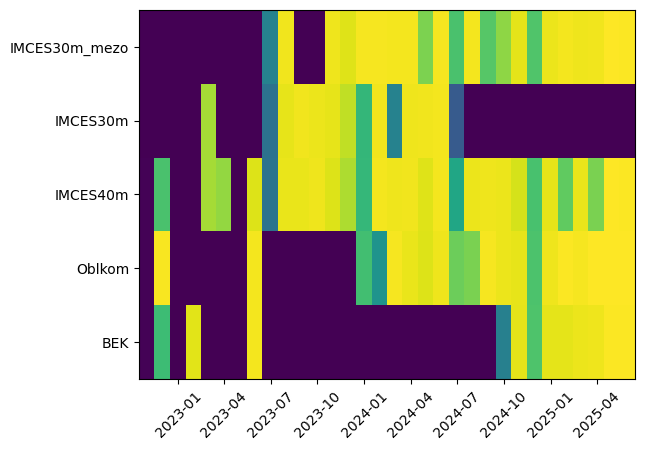

In [14]:
df_is_ok = pd.DataFrame()

for i, site in enumerate (df4sites.keys()):
    df4site = df4sites[site]
    
    is_ok4site = pd.DataFrame(~np.isnan(df4site['H'])).rename(columns = {'H': site})
    df_is_ok = df_is_ok.merge(is_ok4site, how = 'outer', right_index = True, left_index = True)

data = df_is_ok.astype(float).fillna(0).resample('M', label='left').mean()

display(data)

plt.pcolormesh(data.index, data.columns, data.T.to_numpy())
_ = plt.xticks(rotation=45)

export_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/processed/Tomsk_new_" + corr_str
os.makedirs(export_dir, exist_ok=True)

plt.savefig(export_dir + "/data_availibility.png", dpi = 300)

In [ ]:
# df4site = df4sites['IMCES40m']
# ((df4site['rmsw'])/(df4site['ustar'])).median()

1.4295714034341225

In [ ]:
df4site = df4sites['Oblkom']
pd.options.plotting.backend = "plotly"
((df4site['rmsw'])/(df4site['ustar'])).plot()
#plt.plot (psi, (df4site['rmsw']**2)/(df4site['ustar']), 'ok')

In [15]:
# export_dir = "D:/!Work/IFA/!data/Urban_fluxes_NE/processed/Tomsk" + corr_str
# os.makedirs(export_dir, exist_ok=True)

time_shift = pd.Timedelta(7, 'h')

for site in df4sites.keys():
    df4site = df4sites[site]
    df2export = df4site[['H', 'tau', 'uz', 't', 'r', 'P', 'ro', 'u', 'v', 'w', 'V', 'D', 'alfa']]
    df2export = df2export.rename(columns = {'H': 'Qh',
                                            'tau': 'Qtau',
                                            'uz':'Ustar', 
                                            't': 'T_air',
                                            'r': 'RH_air',
                                            'P': 'P_air',
                                            'ro': 'Rho_air',
                                            'Vs':'Wind_V',
                                            'Ve':'Wind_U',
                                            'w':'Wind_W',
                                            'w':'Wind_sigmaW',
                                            'V':'Wind_vel',
                                            'D':'Wind_dir',
                                            'alfa':'Wind_alpha'})
    df2export['P_air'] = df2export['P_air'] * 1013/760
    df2export.index = df2export.index - time_shift
    df2export.to_csv(export_dir + '/' + site +  '.csv')


In [7]:
df = pd.DataFrame()

for site in df4sites.keys():
    df4site = df4sites[site].copy().rename(columns = {c:site + '_' + c for c in df4site.columns}) # if c != '': 'Qh',)
    df = df.merge(df4site, how = 'outer', right_index = True, left_index = True)

